# TabPFN interpretability — feature selection, PDP, consensus

Kaggle time-limit split of `tabpfn_interpretability.ipynb`. **This notebook** is mutual
information, stability SFS, partial dependence, and the consensus ranking.

The SHAP / SHAP-IQ half is `tabpfn_interpretability_shap.ipynb`. Run that separately
(same install, env knobs, leakage cleaning, 70/30 split, TabPFN v3.5). To include
SHAP in the consensus table, copy `interpretability_shap_mean_abs.csv` into
`RESULT_DIR` or attach the SHAP notebook output as a Kaggle input dataset.


# Install TabPFN Extenstions

In [1]:
import importlib.util
import sys

def _missing(mod):
    return importlib.util.find_spec(mod) is None

to_install = []
# `shap` is only needed for the plotting API in the SHAP section — shapiq
# (installed via tabpfn-extensions[all]) does the actual computation.
if _missing("shap"):
    to_install.append("shap")

if to_install:
    print("Installing:", to_install)
    # `-q -q` = silence "Collecting/Downloading" progress lines.
    # `--no-warn-conflicts` = silence pre-existing Kaggle image conflicts
    # (google-colab, moviepy, bigframes, ...) that this notebook doesn't touch.
    get_ipython().run_line_magic("pip", "install -q -q --no-warn-conflicts " + " ".join(to_install))
    print("Done. If imports fail, restart the kernel and re-run.")
else:
    print("shap already available.")

shap already available.


In [2]:
print("Installing tabpfn-extensions[interpretability]... (may take ~1 minute)")
# Only the `interpretability` extra is needed for this notebook.
# `[all]` also pulls autogluon / hyperopt / llvmlite via `post_hoc_ensembles`
# + `hpo`, which are ~150 MB of unrelated deps and downgrade `pyarrow`,
# triggering the pip resolver conflict noise we don't want.
# `-q -q --no-warn-conflicts` silences "Collecting/Downloading" progress
# lines and the pre-existing Kaggle image conflict warnings (google-colab,
# moviepy, bigframes, ...) that this notebook doesn't touch.
# Pinned: an unpinned install let two runs of an unchanged notebook resolve
# different TabPFN packages and checkpoints. Pinned to the latest releases;
# tabpfn 9.2.0 loads the same v3.5 file (tabpfn-v3.5-20260909) as 9.0.0.
TABPFN_PIN = "9.2.0"  # latest release (Nov 2026); same v3.5 checkpoint as 9.0.0
TABPFN_CLIENT_PIN = "0.7.1"  # latest release (Nov 2026)
# Released versions, not GitHub main: the SHAP approximator tabpfn-extensions
# picks depends on the shapiq version (OddSHAP needs shapiq>=1.6.0), so an
# unpinned install can change attributions between runs of the same code.
# Interpretability-only packages are pinned to the newest release on PyPI
# (checked 7 Nov 2026). tabpfn / tabpfn-client stay at the versions the
# benchmark ran with, so the explained model is the benchmarked one.
TABPFN_EXTENSIONS_PIN = "0.6.3"
SHAPIQ_PIN = "1.8.0"
SHAP_PIN = "0.54.1"
%pip install -q -q --no-warn-conflicts "tabpfn-extensions[interpretability]=={TABPFN_EXTENSIONS_PIN}" "shapiq=={SHAPIQ_PIN}" "shap=={SHAP_PIN}"
!pip install -q -q --no-warn-conflicts tabpfn=={TABPFN_PIN} tabpfn-client=={TABPFN_CLIENT_PIN}
print("Done. If imports fail, restart the kernel and re-run.")


Installing tabpfn-extensions[interpretability]... (may take ~1 minute)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.2/123.2 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 85.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.9/555.9 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 868.3/868.3 kB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 45.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 29.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 6.0 MB/s e

### Load env

In [3]:
import os
import sys
import warnings
from contextlib import contextmanager
from io import StringIO

# Silence noisy third-party warnings that clutter the Kaggle logs but are not
# actionable here (emitted from deep inside sklearn / hyperopt during the many
# local TabPFN fits). Set once at import time so it applies to every later cell.
warnings.filterwarnings(
    "ignore",
    message=r"(?s).*remainder.*ColumnTransformer.*",
    category=FutureWarning,
)
warnings.filterwarnings(
    "ignore",
    message=r"(?s).*ColumnTransformer.*force_int_remainder_cols.*",
    category=FutureWarning,
)
warnings.filterwarnings("ignore", category=FutureWarning, module=r"hyperopt.*")
warnings.filterwarnings("ignore", category=UserWarning, module=r"hyperopt.*")

# Auto-detect Kaggle.
is_kaggle_env = os.path.isdir("/kaggle/working")

DEVICE = "cpu"
DEVICE_NAME = "CPU"
_gpu_note = ""

try:
    import torch

    # torch emits noisy "compute capability / sm_XX not supported" UserWarnings
    # on first CUDA touch for GPUs older than the ones the installed wheel was
    # built for (e.g. Kaggle's Tesla P100 = sm_60 with a torch built for
    # sm_70+). We handle the fallback explicitly below, so silence them.
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message=r"(?s).*(compute capability|CUDA capability|sm_\d+).*",
            category=UserWarning,
        )
        if torch.cuda.is_available():
            _major, _minor = torch.cuda.get_device_capability(0)
            _gpu_name = torch.cuda.get_device_name(0)
            _supported = torch.cuda.get_arch_list()  # e.g. ['sm_70', ..., 'sm_120']
            _min_major = min(
                (int(a.removeprefix("sm_")[:-1]) for a in _supported if a.startswith("sm_")),
                default=7,
            )
            if _major >= _min_major:
                DEVICE = "cuda"
                DEVICE_NAME = _gpu_name
            else:
                # Kernel launch would crash -- fall back to CPU with a hint.
                _gpu_note = (
                    f" | note: GPU {_gpu_name} (sm_{_major}{_minor}) is below "
                    f"the installed torch build's minimum (sm_{_min_major}0) -- "
                    f"switch the Kaggle accelerator to T4 x2 for a working GPU"
                )
except Exception:
    pass


def _load_tabpfn_tokens():
    hf = os.environ.get("HF_TOKEN", "").strip()
    tabpfn = os.environ.get("TABPFN_TOKEN", "").strip()
    if tabpfn:
        return hf, tabpfn
    if is_kaggle_env:
        from kaggle_secrets import UserSecretsClient
        secrets = UserSecretsClient()
        hf = secrets.get_secret("HF_TOKEN")
        tabpfn = secrets.get_secret("AMIRINHO661_TABPFN_TOKEN")
        return hf, tabpfn
    return hf, tabpfn

_hf_token, _tabpfn_token = _load_tabpfn_tokens()
if _tabpfn_token:
    os.environ["TABPFN_TOKEN"] = _tabpfn_token
if _hf_token:
    os.environ["HF_TOKEN"] = _hf_token

os.environ["USE_TABPFN_LOCAL"] = "false"

# Hosted quota (Prior Labs default): 5M tokens/day, 20M tokens/month; thinking
# fits draw from the same pool, and every request costs at least 10k tokens. One
# v3.5 effort="high" thinking fit quotes ~5.9M tokens (more than a day's limit),
# so everything below stays local unless the limit is raised.
# Hybrid backend (held-out protocol; see load cell):
#   - FS stability SFS: local `tabpfn` only (STABILITY_N_SEEDS fits).
#   - PDP: local `tabpfn` + KV cache when PDP_USE_CLIENT=False.
#     Sklearn brute PDP has no client KV cache; large grids burn the daily
#     token quota (HTTP 429). If PDP_USE_CLIENT=True, the *entire*
#     PDP (fit + plots) tries the client, then retries locally on failure.
#   - SHAP / SHAP-IQ: SHAP_BACKEND below. "local" = pinned local TabPFN v3.5
#     + KV cache (the model the paper reports). "client" = hosted thinking
#     v3.5; on client failure every row is recomputed locally (never mixed).
# Explaining held-out rows on the client sends >=1 request per row (>=10k tokens each).
# USE_TABPFN_LOCAL=false keeps tabpfn_extensions on the client if imported
# elsewhere; the FS cell imports `from tabpfn import TabPFNClassifier` directly.
FS_THINKING_MODE = False
INTERP_THINKING_MODE = True
INTERP_THINKING_EFFORT = "high"
INTERP_THINKING_METRIC = "average_precision"
SHAP_BACKEND = "local"  # "local" | "client"
# Held-out protocol (set in the load cell): fit / MI / SFS / PDP / SHAP
# background use the train split; SHAP explains the held-out test split.
# k-SII / waterfall use the first VLST=1 row in the held-out split.
SHAP_EXPLAIN_HELDOUT = True
PDP_USE_CLIENT = False
STABILITY_N_SEEDS = 8  # local TabPFN SFS repeats; 4/8 = 0.5 consensus cutoff

# Pin both arms to v3.5 (same checkpoint family as baseline_plus_tabpfn.ipynb).
# The checkpoint is named explicitly rather than left to model_path="auto",
# whose resolution has changed between tabpfn releases.
TABPFN_PIN = "9.2.0"
TABPFN_CLIENT_PIN = "0.7.1"
TABPFN_MODEL_VERSION = "v3.5"
TABPFN_THINKING_VERSION = "v3.5"

# Intended fit budget from the knobs above (happy path; no client failures).
# Client "thinking fits" count only when INTERP_THINKING_MODE is True.
N_CLIENT_THINKING_FITS = 0
_CLIENT_THINKING_PARTS = []
if INTERP_THINKING_MODE:
    if PDP_USE_CLIENT:
        N_CLIENT_THINKING_FITS += 1
        _CLIENT_THINKING_PARTS.append("PDP")
    if SHAP_BACKEND == "client":
        N_CLIENT_THINKING_FITS += 1
        _CLIENT_THINKING_PARTS.append("SHAP")
        N_CLIENT_THINKING_FITS += 1
        _CLIENT_THINKING_PARTS.append("SHAP-IQ")

N_LOCAL_TABPFN_FITS = int(STABILITY_N_SEEDS)  # stability SFS seeds
_LOCAL_TABPFN_PARTS = [f"SFS x{STABILITY_N_SEEDS}"]
if not PDP_USE_CLIENT:
    N_LOCAL_TABPFN_FITS += 1
    _LOCAL_TABPFN_PARTS.append("PDP")
# SHAP / SHAP-IQ local backups are not part of the intended count.


def _silence_client_progress(clf):
    """Prefer the official switch when present (tabpfn-client show_progress)."""
    if hasattr(clf, "show_progress"):
        clf.show_progress = False
    return clf


_LOCAL_TABPFN_LOGGED = False
_CLIENT_TABPFN_LOGGED = False


def build_local_tabpfn(*, n_estimators="auto", random_state=42, fit_mode=None, **kwargs):
    """Local TabPFN v3.5. Extra kwargs overlay the version default."""
    from pathlib import Path as _Path

    from tabpfn import TabPFNClassifier as LocalTabPFNClassifier

    ctor_kwargs = {
        "device": DEVICE,
        "n_estimators": n_estimators,
        "random_state": random_state,
        **kwargs,
    }
    if fit_mode is not None:
        ctor_kwargs["fit_mode"] = fit_mode
    try:
        from tabpfn.constants import ModelVersion

        try:
            clf = LocalTabPFNClassifier.create_default_for_version(
                ModelVersion(TABPFN_MODEL_VERSION), **ctor_kwargs
            )
        except TypeError:
            ctor_kwargs.pop("fit_mode", None)
            clf = LocalTabPFNClassifier.create_default_for_version(
                ModelVersion(TABPFN_MODEL_VERSION), **ctor_kwargs
            )
            if fit_mode is not None:
                try:
                    clf.set_params(fit_mode=fit_mode)
                except (ValueError, TypeError):
                    pass
    except (ImportError, AttributeError, ValueError) as exc:
        raise RuntimeError(
            f"Cannot select TabPFN {TABPFN_MODEL_VERSION} ({type(exc).__name__}: {exc}). "
            f"Install tabpfn=={TABPFN_PIN} to run it."
        ) from exc
    checkpoint = clf.get_params().get("model_path")
    if checkpoint in (None, "auto"):
        raise RuntimeError(
            f"Local TabPFN {TABPFN_MODEL_VERSION} is unpinned (model_path={checkpoint!r}); "
            "refusing to mislabel."
        )
    global _LOCAL_TABPFN_LOGGED
    if not _LOCAL_TABPFN_LOGGED:
        params = clf.get_params()
        print(
            f"TabPFN local {TABPFN_MODEL_VERSION} ready |",
            f"checkpoint={_Path(str(checkpoint)).name}",
            f"device={params.get('device')}",
            f"n_estimators={params.get('n_estimators')}",
            f"balance_probabilities={params.get('balance_probabilities')}",
        )
        _LOCAL_TABPFN_LOGGED = True
    return clf


def build_client_tabpfn(**kwargs):
    """Hosted TabPFN thinking v3.5. Extra kwargs overlay thinking defaults."""
    from tabpfn_client import TabPFNClassifier as ClientTabPFNClassifier

    thinking_kwargs = {
        "thinking_mode": INTERP_THINKING_MODE,
        "thinking_effort": INTERP_THINKING_EFFORT,
        "thinking_metric": INTERP_THINKING_METRIC,
        "random_state": 42,
        **kwargs,
    }
    try:
        clf = ClientTabPFNClassifier.create_default_for_version(
            TABPFN_THINKING_VERSION, **thinking_kwargs
        )
    except (AttributeError, ValueError, TypeError) as exc:
        raise RuntimeError(
            f"Cannot select hosted TabPFN {TABPFN_THINKING_VERSION} "
            f"({type(exc).__name__}: {exc}). Install tabpfn-client=={TABPFN_CLIENT_PIN}."
        ) from exc
    served = clf.get_params().get("model_path")
    if served in (None, "auto", "default"):
        raise RuntimeError(
            f"Hosted TabPFN {TABPFN_THINKING_VERSION} deferred to the server default; "
            "arm skipped rather than mislabelled."
        )
    global _CLIENT_TABPFN_LOGGED
    if not _CLIENT_TABPFN_LOGGED:
        print(
            f"TabPFN thinking {TABPFN_THINKING_VERSION} ready |",
            f"server model={served}",
            f"effort={thinking_kwargs['thinking_effort']}",
            f"metric={thinking_kwargs['thinking_metric']}",
        )
        _CLIENT_TABPFN_LOGGED = True
    return clf


# --- Provenance and SHAP output scale ----------------------------------------
# Every interpretability artefact records which model produced it in
# RESULT_DIR / interpretability_model_provenance.json (backend, checkpoint,
# package versions, settings, output scale).
SHAP_SCALE_LABELS = {
    "logit": "class-1 logit (pre-softmax score)",
    "probability": "P[VLST]",
}
SHAP_SCALE_LABEL = "model output (scale not yet checked)"


def describe_tabpfn_model(clf, backend):
    """Constructor settings and package versions of a fitted TabPFN model."""
    from importlib.metadata import PackageNotFoundError, version as _dist_version
    from pathlib import Path as _Path

    def _pkg(name):
        try:
            return _dist_version(name)
        except PackageNotFoundError:
            return None

    params = clf.get_params() if hasattr(clf, "get_params") else {}
    model_path = params.get("model_path")
    is_local = str(backend).startswith("local")
    return {
        "backend": backend,
        "class": f"{type(clf).__module__}.{type(clf).__name__}",
        "requested_version": TABPFN_MODEL_VERSION if is_local else TABPFN_THINKING_VERSION,
        "model_path": None if model_path is None else str(model_path),
        "checkpoint": None if model_path is None else _Path(str(model_path)).name,
        "n_estimators": params.get("n_estimators"),
        "fit_mode": params.get("fit_mode"),
        "random_state": params.get("random_state"),
        "device": params.get("device"),
        "thinking_mode": params.get("thinking_mode"),
        "thinking_effort": params.get("thinking_effort"),
        "thinking_metric": params.get("thinking_metric"),
        "packages": {
            "tabpfn": _pkg("tabpfn"),
            "tabpfn-client": _pkg("tabpfn-client"),
            "tabpfn-extensions": _pkg("tabpfn-extensions"),
            "shapiq": _pkg("shapiq"),
            "scikit-learn": _pkg("scikit-learn"),
        },
    }


def record_provenance(component, info):
    """Merge one component's record into the provenance JSON and print a summary."""
    import json as _json
    from datetime import datetime, timezone

    path = RESULT_DIR / "interpretability_model_provenance.json"
    try:
        data = _json.loads(path.read_text())
    except (FileNotFoundError, ValueError):
        data = {}
    data[component] = {
        **info,
        "recorded_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    path.write_text(_json.dumps(data, indent=2, default=str))
    _keys = ("backend", "checkpoint", "n_estimators", "fit_mode", "output_scale")
    _summary = {k: info[k] for k in _keys if k in info} or sorted(info)
    print(f"Provenance [{component}]:", _summary, "->", path)


def detect_shap_output_scale(clf, ivs, X_rows, n_check=25):
    """Which model output the Shapley values add up to.

    Efficiency: baseline_value + sum(first-order values) = model output at x.
    shapiq explains predict_logits when the model has it (local TabPFN) and
    predict_proba otherwise, so the scale depends on the backend. Both
    candidates are compared on the first n_check rows; the closer one wins.
    """
    k = min(n_check, len(ivs))
    recon = np.array(
        [float(iv.baseline_value) + float(np.sum(iv.get_n_order_values(1))) for iv in ivs[:k]]
    )
    X_chk = np.asarray(X_rows)[:k]
    candidates = {}
    with _quiet_tabpfn_client():
        candidates["probability"] = np.asarray(clf.predict_proba(X_chk))[:, 1]
        if hasattr(clf, "predict_logits"):
            try:
                candidates["logit"] = np.asarray(clf.predict_logits(X_chk))[:, 1]
            except Exception as exc:  # report, do not guess
                print(f"predict_logits unavailable for the scale check: {exc}")
    errors = {name: float(np.max(np.abs(recon - vals))) for name, vals in candidates.items()}
    scale = min(errors, key=errors.get)
    return {
        "output_scale": scale,
        "max_abs_reconstruction_error": errors,
        "n_checked": int(k),
    }


def print_runtime_versions():
    """Installed versions as actually imported (not the requested pins)."""
    import platform
    from importlib.metadata import PackageNotFoundError, version as _dist_version

    names = (
        "tabpfn", "tabpfn-client", "tabpfn-extensions", "shapiq", "shap",
        "scikit-learn", "numpy", "pandas", "torch",
    )
    found = {}
    for name in names:
        try:
            found[name] = _dist_version(name)
        except PackageNotFoundError:
            found[name] = None
    print("Python", platform.python_version(), "|", "; ".join(f"{k}={v}" for k, v in found.items()))
    for name, want in (
        ("tabpfn", TABPFN_PIN),
        ("tabpfn-client", TABPFN_CLIENT_PIN),
        ("tabpfn-extensions", globals().get("TABPFN_EXTENSIONS_PIN")),
        ("shapiq", globals().get("SHAPIQ_PIN")),
    ):
        if want and found.get(name) != want:
            print(f"WARNING: {name} {found.get(name)} installed, {want} pinned -- restart the kernel after install.")
    return {"python": platform.python_version(), **found}


@contextmanager
def _quiet_tabpfn_client():
    """Discard tabpfn-client Fitting/Predicting spinner writes to stdout.

    Does not silence our own print() trackers -- only wrap fit/predict/explain
    blocks that trigger the client's run_task spinner.
    """
    _real_stdout = sys.stdout
    try:
        sys.stdout = StringIO()
        yield
    finally:
        sys.stdout = _real_stdout


# --- Plot helpers (readable PDP / k-SII networks) ---------------------------
KSII_NETWORK_TOP_K = 20          # only plot the top-|SV| features in networks
KSII_NETWORK_FIGSIZE = (18, 18)  # large canvas so labels do not collide
KSII_NETWORK_DPI = 200


def _polish_figure(fig, *, title: str | None = None, fontsize: int = 12):
    """Enlarge a matplotlib figure and make titles/labels readable."""
    import matplotlib.pyplot as plt

    if fig is None:
        fig = plt.gcf()
    w, h = fig.get_size_inches()
    fig.set_size_inches(max(w, 10), max(h, 7))
    if title:
        fig.suptitle(title, fontsize=fontsize + 2, y=1.02)
    for ax in fig.axes:
        ax.title.set_fontsize(fontsize)
        ax.xaxis.label.set_fontsize(fontsize)
        ax.yaxis.label.set_fontsize(fontsize)
        ax.tick_params(axis="both", labelsize=fontsize - 1)
        for lbl in ax.get_xticklabels() + ax.get_yticklabels():
            lbl.set_fontsize(fontsize - 1)
    fig.tight_layout()
    return fig


def _ksii_subset_for_plot(iv, names: list[str], k: int = KSII_NETWORK_TOP_K):
    """Keep top-k features by |first-order SV| and remap indices to 0..k-1.

    shapiq's ``get_subset`` keeps original player ids and has a buggy
    ``n_players``; remapping avoids empty slots and label collisions.
    """
    import numpy as np
    from shapiq import InteractionValues

    fo = np.abs(iv.get_n_order_values(1))
    k = int(min(k, fo.size))
    top = np.argsort(fo)[::-1][:k].tolist()
    remap = {old: new for new, old in enumerate(top)}
    top_names = [names[i] for i in top]

    new_lookup: dict = {}
    new_values: list = []
    for key, val in iv.dict_values.items():
        if not all(p in remap for p in key):
            continue
        new_key = tuple(sorted(remap[p] for p in key))
        if new_key in new_lookup:
            continue
        new_lookup[new_key] = len(new_values)
        new_values.append(float(val))

    sub = InteractionValues(
        values=np.asarray(new_values, dtype=float),
        interaction_lookup=new_lookup,
        index=iv.index,
        max_order=iv.max_order,
        n_players=k,
        min_order=iv.min_order,
        baseline_value=iv.baseline_value,
        estimated=getattr(iv, "estimated", True),
        estimation_budget=getattr(iv, "estimation_budget", None),
    )
    return sub, top_names, top


def _plot_ksii_network_readable(
    iv,
    names: list[str],
    out_path,
    *,
    k: int = KSII_NETWORK_TOP_K,
    title: str | None = None,
):
    """Large k-SII network with only the top-k features (readable labels)."""
    import matplotlib.pyplot as plt

    sub, top_names, top_idx = _ksii_subset_for_plot(iv, names, k=k)
    print(
        f"k-SII network: showing top {len(top_names)} features by |SV|: {top_names}"
    )
    result = sub.plot_network(
        feature_names=top_names,
        show=False,
        n_interactions=min(40, len(top_names) * 3),
        size_factor=1.6,
        node_size_scaling=1.4,
    )
    if result is None:
        fig, ax = plt.gcf(), plt.gca()
    else:
        fig, ax = result
    fig.set_size_inches(*KSII_NETWORK_FIGSIZE)
    for t in ax.texts:
        t.set_fontsize(11)
        t.set_fontweight("bold")
    _title = title or (
        f"k-SII interaction network — top {len(top_names)} features by |SV| "
        f"({SHAP_SCALE_LABEL}, one row)"
    )
    fig.suptitle(_title, fontsize=14, y=0.98)
    # Extra margin so radial labels are not clipped
    fig.subplots_adjust(left=0.08, right=0.92, top=0.92, bottom=0.08)
    fig.savefig(out_path, dpi=KSII_NETWORK_DPI, bbox_inches="tight", pad_inches=0.4)
    plt.show()
    print(f"Saved: {out_path}")
    return top_names, top_idx


def _plot_ksii_upset_readable(
    iv,
    names: list[str],
    out_path,
    *,
    n_interactions: int = 20,
    title: str | None = None,
):
    """Tall, readable k-SII UpSet plot (only features in the top interactions).

    Key: ``all_features=False`` — otherwise ~81 y-labels collide. Leave height
    automatic (``figsize=(width, None)``) so shapiq uses
    ``height ≈ 5 + n_features * 0.75`` like the library's own examples.
    """
    import matplotlib.pyplot as plt

    _title = title or (
        f"k-SII upset — top {n_interactions} main effects & pairwise "
        "interactions (one row; rows = features in those interactions only)"
    )
    # Width fixed; height=None → shapiq auto-scales for readable row labels.
    fig = iv.plot_upset(
        feature_names=list(names),
        n_interactions=n_interactions,
        all_features=False,
        figsize=(14, None),
        show=False,
    )
    if fig is None:
        fig = plt.gcf()
    fig.suptitle(_title, fontsize=14, y=1.01)
    for ax in fig.axes:
        ax.tick_params(axis="y", labelsize=11)
        for lbl in ax.get_yticklabels():
            lbl.set_fontsize(11)
            lbl.set_fontweight("bold")
    fig.savefig(out_path, dpi=KSII_NETWORK_DPI, bbox_inches="tight", pad_inches=0.35)
    plt.show()
    print(f"Saved: {out_path}  (size={fig.get_size_inches()})")
    return fig


print(
    f"Runtime: {'Kaggle' if is_kaggle_env else 'local'} | "
    f"TabPFN device: {DEVICE} ({DEVICE_NAME}) | "
    f"Tokens: {bool(_tabpfn_token) and bool(_hf_token)}"
    f"{_gpu_note}"
)
print(
    "Quota (client): 5M tokens/day | 20M tokens/month (thinking fits share the pool)"
)
print(
    f"Intended client thinking fits: {N_CLIENT_THINKING_FITS}"
    + (
        f" ({', '.join(_CLIENT_THINKING_PARTS)})"
        if _CLIENT_THINKING_PARTS
        else " (none)"
    )
    + f"; SHAP_BACKEND={SHAP_BACKEND!r} (client failure -> all rows recomputed locally)."
)
print(
    f"Intended local TabPFN fits: {N_LOCAL_TABPFN_FITS} "
    f"({', '.join(_LOCAL_TABPFN_PARTS)}; MI/report = 0 TabPFN)"
)
print(
    f"Thinking: FS={FS_THINKING_MODE} (local {TABPFN_MODEL_VERSION}) | PDP_USE_CLIENT={PDP_USE_CLIENT} | "
    f"SHAP/SHAP-IQ backend={SHAP_BACKEND} "
    f"(effort={INTERP_THINKING_EFFORT}, metric={INTERP_THINKING_METRIC}, "
    f"version={TABPFN_THINKING_VERSION})"
)
print(
    f"TabPFN pins: tabpfn=={TABPFN_PIN} tabpfn-client=={TABPFN_CLIENT_PIN} | "
    f"local={TABPFN_MODEL_VERSION} thinking={TABPFN_THINKING_VERSION}"
)
print(
    "Interpretability protocol: fit on stratified train; "
    "SHAP explains held-out test; "
    "k-SII / waterfall = first held-out VLST=1"
)
RUNTIME_VERSIONS = print_runtime_versions()


Runtime: Kaggle | TabPFN device: cuda (Tesla T4) | Tokens: True
Quota (client): 5M tokens/day | 20M tokens/month (thinking fits share the pool)
Intended client thinking fits: 0 (none); SHAP_BACKEND='local' (client failure -> all rows recomputed locally).
Intended local TabPFN fits: 9 (SFS x8, PDP; MI/report = 0 TabPFN)
Thinking: FS=False (local v3.5) | PDP_USE_CLIENT=False | SHAP/SHAP-IQ backend=local (effort=high, metric=average_precision, version=v3.5)
TabPFN pins: tabpfn==9.2.0 tabpfn-client==0.7.1 | local=v3.5 thinking=v3.5
Interpretability protocol: fit on stratified train; SHAP explains held-out test; k-SII / waterfall = first held-out VLST=1
Python 3.12.13 | tabpfn=9.2.0; tabpfn-client=0.7.1; tabpfn-extensions=0.6.3; shapiq=1.8.0; shap=0.54.1; scikit-learn=1.6.1; numpy=2.0.2; pandas=2.3.3; torch=2.10.0+cu128


### Load data

Stratified train / held-out split (`TEST_SIZE`, `RANDOM_STATE`). Later cells
**fit** on train and **explain** on held-out test — not the full cohort.

File-level cleaning matches `baseline_plus_tabpfn.ipynb`: drop identifiers,
`Time since stent implantation`, and `WBC`; quantize labs whose recording
precision is a case/control batch marker (`Cre`, `CaI`, `Fiberinogen`,
`Fast-Glu`). Stent-brand collapse (`min_count=30`) and categorical integer
codes are fit on **train only**; held-out strings map to `other` / unseen → NaN.
Follow-up drugs stay in. Both TabPFN arms are **v3.5**.

The stent-brand codebook is fitted on the **training split only**. With the R1 switches on (default),
`Aspirin` / `Clopidogrel` / `Ticagrelor` / `DAPT` are dropped and `eGFR` / `CKD5` / `CKD60` / `CKD90` are
recalculated from `Cre`, `Age`, `Men`; outputs go to a `_r1_postpci` result directory.


In [4]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_MODE = "raw"            # "raw" (spec default) or "processed"

TARGET_COL = "Stent thrombosis"
# Same status as dropping TSSI: file-level cleaning, not a parameter fit on y.
DROP_FEATURES = [
    "Time since stent implantation",  # time-at-risk / follow-up, not a baseline covariate
    "WBC",  # recording-precision lattice + magnitude is a case/control batch marker
]
# R1 switches, same meaning as in baseline_plus_tabpfn.ipynb. Both True = the
# post-PCI, artefact-reduced matrix; both False reproduces the earlier run.
DROP_FOLLOWUP_MEDICATIONS = True  # Aspirin / Clopidogrel / Ticagrelor / DAPT are follow-up fields
RECOMPUTE_EGFR_FROM_CREATININE = True
FOLLOWUP_MEDICATION_COLUMNS = ["Aspirin", "Clopidogrel", "Ticagrelor", "DAPT"]
if DROP_FOLLOWUP_MEDICATIONS:
    DROP_FEATURES += FOLLOWUP_MEDICATION_COLUMNS
# R3 switch, same meaning as in baseline_plus_tabpfn.ipynb: drop CaI (the value
# 0.034 is stored for 20/92 cases vs 10/5,093 controls) and round LV to 5 mm bins
# (its last digit differs by outcome). Set it to match the benchmark run you explain.
# Main analysis from 9 Nov 2026; False reproduces the R1 run.
R3_RESIDUAL_ARTEFACTS = True
# CaI under R3. "drop" (main): CaI leaves the matrix. "censor" (sensitivity): CaI
# stays, with every value below 0.1 set to 0.1, so the 0.034 placeholder cannot be
# told apart from the controls' 0.01-0.09 values while larger troponins keep their
# magnitude. The share below 0.1 still differs (21/92 vs 277/5,093), and whether
# that is real or the placeholder cannot be settled, so "censor" is not the default.
R3_CAI_HANDLING = "drop"  # "drop" | "censor"
CAI_CENSOR_FLOOR = 0.1
if R3_CAI_HANDLING not in ("drop", "censor"):
    raise ValueError(f"R3_CAI_HANDLING must be 'drop' or 'censor', not {R3_CAI_HANDLING!r}")
if R3_RESIDUAL_ARTEFACTS and R3_CAI_HANDLING == "drop":
    DROP_FEATURES += ["CaI"]
if DROP_FOLLOWUP_MEDICATIONS and RECOMPUTE_EGFR_FROM_CREATININE:
    ANALYSIS_TAG = (
        ("r3_residual" if R3_CAI_HANDLING == "drop" else "r3_caicensor")
        if R3_RESIDUAL_ARTEFACTS else "r1_postpci"
    )
elif not (DROP_FOLLOWUP_MEDICATIONS or RECOMPUTE_EGFR_FROM_CREATININE):
    ANALYSIS_TAG = "primary_r3" if R3_RESIDUAL_ARTEFACTS else "primary"
else:
    ANALYSIS_TAG = "custom_meds{}_egfr{}_r3{}".format(
        int(DROP_FOLLOWUP_MEDICATIONS), int(RECOMPUTE_EGFR_FROM_CREATININE), int(R3_RESIDUAL_ARTEFACTS)
    )
ID_COLS = ["NO.", "Name"]
RANDOM_STATE = 42
TEST_SIZE = 0.3
STENT_BRAND_COL = "Stent type-SES"

# Pre-declared clinical grids for labs whose raw text precision is a
# case/control batch marker. Same status as dropping TSSI: a file-level
# cleaning rule, not a parameter fit on y.
#   Cre 0 dp  — µmol/L; integer is standard
#   CaI 2 dp  — ng/mL conventional TnI; refuse case-only thousandths
#   Fiberinogen / Fast-Glu 1 dp — g/L and mmol/L
CLINICAL_QUANTIZE_PLACES = {
    "Cre": 0,
    "CaI": 2,
    "Fiberinogen": 1,
    "Fast-Glu": 1,
}


def quantize_clinical_precision(frame, places_by_column):
    """Round listed numeric columns in-place; return the columns actually changed."""
    applied = {}
    for column, places in places_by_column.items():
        if column not in frame.columns:
            continue
        if not pd.api.types.is_numeric_dtype(frame[column]):
            continue
        before = pd.to_numeric(frame[column], errors="coerce")
        rounded = before.round(int(places))
        frame[column] = rounded
        n_changed = int((before != rounded).fillna(False).sum())
        applied[column] = {"places": int(places), "n_changed": n_changed}
    return applied


# R1: recorded eGFR is not a function of recorded Cre for most controls, and
# the mismatch differs by outcome. Rebuild it (and CKD5 / CKD60 / CKD90) from
# the quantized Cre. Reads only the patient's own row, never y, so it is a
# file-level rule like the quantization above. In-notebook copy of
# code/modeling/tools/egfr_recompute.py. Assumes Cre in umol/L (pending
# custodian confirmation).
def recompute_egfr_from_creatinine(frame):
    """Overwrite eGFR / CKD5 / CKD60 / CKD90 in place with CKD-EPI 2009 values."""
    recorded = pd.to_numeric(frame["eGFR"], errors="coerce").to_numpy(dtype=float)
    scr = pd.to_numeric(frame["Cre"], errors="coerce").to_numpy(dtype=float) / 88.4
    age = pd.to_numeric(frame["Age"], errors="coerce").to_numpy(dtype=float)
    male = pd.to_numeric(frame["Men"], errors="coerce").eq(1).to_numpy()
    kappa = np.where(male, 0.9, 0.7)
    alpha = np.where(male, -0.411, -0.329)
    ratio = scr / kappa
    egfr = np.round(
        141.0 * np.minimum(ratio, 1.0) ** alpha * np.maximum(ratio, 1.0) ** -1.209
        * 0.993 ** age * np.where(male, 1.0, 1.018),
        1,
    )
    frame["eGFR"] = egfr
    if "CKD5" in frame.columns:
        frame["CKD5"] = np.select([egfr >= 90, egfr >= 60, egfr >= 30, egfr >= 15], [1, 2, 3, 4], default=5)
    if "CKD60" in frame.columns:
        frame["CKD60"] = (egfr < 60).astype(int)
    if "CKD90" in frame.columns:
        frame["CKD90"] = (egfr < 90).astype(int)
    return {
        "equation": "CKD-EPI 2009 (no race term), Cre umol/L / 88.4",
        "n_recorded_within_1": int(np.sum(np.abs(recorded - egfr) <= 1.0)),
        "recorded_mean": float(np.nanmean(recorded)),
        "recomputed_mean": float(np.nanmean(egfr)),
    }

KAGGLE_RAW_CSV = "/kaggle/input/datasets/amirinho661/vlst-figshare-7409606/VLST.csv"
KAGGLE_PROCESSED_DIR = "/kaggle/input/datasets/amirmahdidaraei/preprocessed-data"
KAGGLE_RESULT_SUBDIR = "modeling_tabpfn" if ANALYSIS_TAG == "primary" else f"modeling_tabpfn_{ANALYSIS_TAG}"
RESULT_DIR = None  # resolved in the load cell

def _find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for d in (here, *here.parents):
        if (d / "data" / "raw" / "VLST.csv").is_file():
            return d
    raise FileNotFoundError(
        "Could not locate data/raw/VLST.csv above the current working directory."
    )


def _discover_vlst_csv() -> Path:
    """Resolve VLST.csv on Kaggle (env override, then recursive search under /kaggle/input)."""
    env = os.environ.get("VLST_RAW_CSV")
    if env and Path(env).is_file():
        return Path(env)

    candidates = [
        Path(KAGGLE_RAW_CSV),
        Path("/kaggle/input/datasets/amirmahdidaraei/vlst-data/VLST.csv"),
        Path("/kaggle/input/vlst-data/VLST.csv"),
        Path("/kaggle/input/VLST_data/VLST.csv"),
        Path("/kaggle/input/datasets/amirinho661/vlst-figshare-7409606/VLST.csv")
    ]
    for p in candidates:
        if p.is_file():
            return p

    base = Path("/kaggle/input")
    if base.is_dir():
        for p in base.rglob("VLST.csv"):
            if p.is_file():
                return p

    raise FileNotFoundError(
        "VLST.csv not found on Kaggle. Upload it as a dataset (see §0) or set "
        "os.environ['VLST_RAW_CSV'] = '/kaggle/input/<dataset>/VLST.csv'."
    )


def _resolve_paths():
    """Return (raw_path, processed_dir, result_dir, label) for local or Kaggle."""
    if is_kaggle_env:
        raw = _discover_vlst_csv()
        processed = Path(
            os.environ.get("VLST_PROCESSED_DIR", KAGGLE_PROCESSED_DIR)
        )
        result = Path(
            os.environ.get(
                "VLST_RESULT_DIR",
                str(Path("/kaggle/working") / KAGGLE_RESULT_SUBDIR),
            )
        )
        return raw, processed, result, f"Kaggle | raw={raw}"

    repo = _find_repo_root()
    return (
        repo / "data" / "raw" / "VLST.csv",
        repo / "data" / "processed",
        repo / "data" / "result" / KAGGLE_RESULT_SUBDIR,
        f"local | repo={repo}",
    )


RAW_PATH, PROCESSED_DIR, RESULT_DIR, _path_label = _resolve_paths()
RESULT_DIR = Path(RESULT_DIR)
PROCESSED_DIR = Path(PROCESSED_DIR)
RAW_PATH = Path(RAW_PATH)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
print(_path_label)
print("Analysis variant:", ANALYSIS_TAG)
print("RAW_PATH:", RAW_PATH)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("RESULT_DIR:", RESULT_DIR)



def _load_stent_encoding():
    """Import the shared 9-level stent-brand encoder.

    On Kaggle the repo tree is usually missing, so this falls back to an
    in-notebook copy of ``code/modeling/tools/stent_encoding.py``.
    """
    import re
    import sys
    from pathlib import Path

    search_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for extra in (
        Path("/kaggle/working"),
        Path("/kaggle/input"),
        Path("/kaggle/usr/lib"),
    ):
        if extra.is_dir():
            search_roots.append(extra)
            search_roots.extend(extra.glob("*"))

    for d in search_roots:
        for tools in (
            d / "code" / "modeling" / "tools",
            d / "modeling" / "tools",
            d,
        ):
            if (Path(tools) / "stent_encoding.py").is_file():
                tools = Path(tools)
                if str(tools) not in sys.path:
                    sys.path.insert(0, str(tools))
                try:
                    from stent_encoding import (
                        encode_stent_brand_column,
                        coerce_stent_class_flags,
                        fit_stent_brand_encoder,
                        transform_stent_brand_column,
                    )
                except ImportError:
                    continue
                print("Stent encoder: imported from", tools / "stent_encoding.py")
                return (
                    encode_stent_brand_column,
                    coerce_stent_class_flags,
                    fit_stent_brand_encoder,
                    transform_stent_brand_column,
                )

    print("Stent encoder: using in-notebook fallback (Kaggle / no repo tree).")

    STENT_BRAND_RAW_COL = "Stent type-SES"
    STENT_CLASS_FLAG_COLS = ("PES", "ZES", "EVS")
    STENT_BRAND_MIN_COUNT = 30
    _BRAND_ALIASES = {
        "xiencex": "xiencev",
        "resolut": "resolute",
        "parnter": "partner",
        "endeavor": "endeavor",
        "cypher": "cypher",
    }

    def canonicalize_stent_brand(value):
        if pd.isna(value) or str(value).strip() == "":
            return "missing"
        s = str(value).strip().replace("：", ":").lower()
        s = re.sub(r"\s+", "", s)
        if ":" in s:
            s = s.split(":")[-1]
        for sep in ("，", ",", "/"):
            if sep in s:
                s = s.split(sep)[0]
        return _BRAND_ALIASES.get(s, s)

    def collapse_rare_brands(series, min_count=STENT_BRAND_MIN_COUNT):
        counts = series.value_counts()
        rare = set(counts[counts < min_count].index)
        if not rare:
            return series
        return series.where(~series.isin(rare), "other")

    def encode_stent_brand_column(df, *, raw_col=STENT_BRAND_RAW_COL, min_count=STENT_BRAND_MIN_COUNT, inplace=False):
        out = df if inplace else df.copy()
        meta = {
            "column": raw_col,
            "n_raw": 0,
            "n_levels": 0,
            "min_count": min_count,
            "applied": False,
            "value_counts": {},
        }
        if raw_col not in out.columns:
            return out, meta
        raw = out[raw_col]
        if pd.api.types.is_numeric_dtype(raw):
            meta["n_raw"] = int(raw.nunique(dropna=True))
            meta["n_levels"] = meta["n_raw"]
            return out, meta
        n_raw = int(raw.nunique(dropna=True))
        encoded = collapse_rare_brands(raw.map(canonicalize_stent_brand), min_count)
        out[raw_col] = encoded.astype("object")
        meta.update({
            "n_raw": n_raw,
            "n_levels": int(encoded.nunique(dropna=True)),
            "applied": True,
            "value_counts": encoded.value_counts().to_dict(),
        })
        return out, meta

    def coerce_stent_class_flags(df):
        out = df
        for col in STENT_CLASS_FLAG_COLS:
            if col not in out.columns:
                continue
            s = pd.to_numeric(out[col], errors="coerce").fillna(0).astype(int)
            bad = ~s.isin([0, 1])
            if bad.any():
                raise ValueError(f"{col}: expected 0/1 after coercion, got {out.loc[bad, col].unique()[:10]}")
            out[col] = s
        return out

    def fit_stent_brand_encoder(series, min_count=STENT_BRAND_MIN_COUNT):
        meta = {
            "min_count": min_count,
            "numeric": False,
            "kept": set(),
            "n_raw": 0,
            "n_levels": 0,
            "applied": False,
            "value_counts": {},
        }
        if pd.api.types.is_numeric_dtype(series):
            n = int(series.nunique(dropna=True))
            meta.update({"numeric": True, "n_raw": n, "n_levels": n})
            return meta
        canon = series.map(canonicalize_stent_brand)
        counts = canon.value_counts()
        kept = set(counts[counts >= min_count].index)
        meta.update({
            "kept": kept,
            "n_raw": int(series.nunique(dropna=True)),
            "n_levels": int(len(kept) + int((counts < min_count).any())),
            "applied": True,
            "value_counts": counts.to_dict(),
        })
        return meta

    def transform_stent_brand_column(frame, codebook, raw_col=STENT_BRAND_RAW_COL, inplace=False):
        out = frame if inplace else frame.copy()
        if raw_col not in out.columns or codebook.get("numeric") or not codebook.get("applied"):
            return out
        canon = out[raw_col].map(canonicalize_stent_brand)
        kept = codebook["kept"]
        out[raw_col] = canon.where(canon.isin(kept), "other").astype("object")
        return out

    return (
        encode_stent_brand_column,
        coerce_stent_class_flags,
        fit_stent_brand_encoder,
        transform_stent_brand_column,
    )


(
    encode_stent_brand_column,
    coerce_stent_class_flags,
    fit_stent_brand_encoder,
    transform_stent_brand_column,
) = _load_stent_encoding()


def encode_stent_on_fold(X_train, X_val, raw_col=STENT_BRAND_COL, min_count=30):
    """Collapse rare brands from training counts only. Unseen val brands -> other."""
    if raw_col not in X_train.columns:
        return X_train, X_val, {"applied": False, "n_raw": 0, "n_levels": 0, "min_count": min_count}
    codebook = fit_stent_brand_encoder(X_train[raw_col], min_count=min_count)
    return (
        transform_stent_brand_column(X_train, codebook, raw_col=raw_col),
        transform_stent_brand_column(X_val, codebook, raw_col=raw_col),
        codebook,
    )


from sklearn.model_selection import train_test_split


def heldout_split_indices(y):
    """Stratified train / held-out row indices shared by every later cell."""
    train_idx, test_idx = train_test_split(
        np.arange(len(y)),
        test_size=TEST_SIZE,
        stratify=y,
        random_state=RANDOM_STATE,
    )
    return np.asarray(train_idx, dtype=int), np.asarray(test_idx, dtype=int)


def load_raw():
    """Minimal, TabPFN-native handling: keep NaNs, code text columns, no scaling/one-hot.

    File-level cleaning matches baseline_plus_tabpfn.ipynb: quantize the listed
    labs, optionally rebuild eGFR from Cre (R1), then collapse brand text to
    levels learned on the training split only (unseen held-out brands ->
    "other"), so integer codes are a nominal codebook, not 106 arbitrary strings.
    Earlier runs skipped the quantization and fitted the codebook on all rows.
    """
    df = pd.read_csv(RAW_PATH)
    df = coerce_stent_class_flags(df)
    _applied = quantize_clinical_precision(df, CLINICAL_QUANTIZE_PLACES)
    print(
        "Clinical quantization (file-level, before split):",
        ", ".join(
            f"{col}->{meta['places']}dp ({meta['n_changed']} values changed)"
            for col, meta in _applied.items()
        ),
    )
    if RECOMPUTE_EGFR_FROM_CREATININE:
        _egfr = recompute_egfr_from_creatinine(df)
        print(
            "eGFR recalculated from Cre:",
            f"{_egfr['n_recorded_within_1']}/{len(df)} recorded values were within 1 unit;",
            f"mean {_egfr['recorded_mean']:.1f} -> {_egfr['recomputed_mean']:.1f}",
        )
    if R3_RESIDUAL_ARTEFACTS:
        df["LV"] = (pd.to_numeric(df["LV"], errors="coerce") / 5).round() * 5
        if R3_CAI_HANDLING == "censor":
            df["CaI"] = pd.to_numeric(df["CaI"], errors="coerce").clip(lower=CAI_CENSOR_FLOOR)
            print(f"R3: CaI below {CAI_CENSOR_FLOOR} set to {CAI_CENSOR_FLOOR}; LV rounded to 5 mm bins.")
        else:
            print("R3: CaI dropped; LV rounded to 5 mm bins.")
    _train_rows, _ = heldout_split_indices(df[TARGET_COL].astype(int).to_numpy())
    if STENT_BRAND_COL in df.columns:
        _codebook = fit_stent_brand_encoder(df[STENT_BRAND_COL].iloc[_train_rows], min_count=30)
        df = transform_stent_brand_column(df, _codebook, raw_col=STENT_BRAND_COL)
        print(
            f"Stent brand (train split only): {_codebook['n_raw']} raw strings -> "
            f"{_codebook['n_levels']} levels (min_count={_codebook['min_count']})"
        )
    df = df.drop(columns=[c for c in ID_COLS if c in df.columns])
    y = df[TARGET_COL].astype(int).to_numpy()
    drop = [TARGET_COL] + [c for c in DROP_FEATURES if c in df.columns]
    X_df = df.drop(columns=drop)
    for c in X_df.columns:
        if X_df[c].dtype == object:
            coerced = pd.to_numeric(X_df[c].astype(str).str.strip(), errors="coerce")
            if coerced.notna().mean() >= 0.5:        # genuinely numeric (e.g. "21.00 ")
                X_df[c] = coerced
            else:                                     # categorical text -> integer codes (NOT one-hot)
                codes = X_df[c].astype("category").cat.codes.astype(float)
                X_df[c] = codes.where(codes >= 0, np.nan)
    return X_df.to_numpy(dtype=float), y, list(X_df.columns)

X_all, y_all, feature_names = load_raw()
print("Loaded RAW VLST.csv")

print(f"X: {X_all.shape} | y: {y_all.shape} | Features: {len(feature_names)}")
print(
    f"Events: {int(np.asarray(y_all).sum())} / {len(y_all)} "
    f"({float(np.mean(y_all)):.4f})"
)
if "Stent type-SES" in feature_names:
    _j = feature_names.index("Stent type-SES")
    _codes = np.unique(X_all[:, _j][~np.isnan(X_all[:, _j])])
    print(
        f"Stent type-SES after 9-level encoder: "
        f"{len(_codes)} integer codes { [int(v) for v in _codes] } "
        f"(TabPFN-native; not 106 raw strings, not one-hot)"
    )


# Held-out protocol for every later cell: fit on train, explain on test.
# Same indices the stent codebook was fitted on inside load_raw().
_train_idx, _test_idx = heldout_split_indices(y_all)
X_train = np.asarray(X_all)[_train_idx]
y_train = np.asarray(y_all)[_train_idx]
X_test = np.asarray(X_all)[_test_idx]
y_test = np.asarray(y_all)[_test_idx]

print(
    f"Split: train n={len(y_train)} (events={int(y_train.sum())}) | "
    f"held-out n={len(y_test)} (events={int(y_test.sum())}) | "
    f"TEST_SIZE={TEST_SIZE} seed={RANDOM_STATE}"
)
pd.DataFrame({"row_index": _train_idx, "vlst": y_train, "split": "train"}).to_csv(
    RESULT_DIR / "interpretability_train_indices.csv", index=False
)
pd.DataFrame({"row_index": _test_idx, "vlst": y_test, "split": "test"}).to_csv(
    RESULT_DIR / "interpretability_heldout_indices.csv", index=False
)
import hashlib

RAW_SHA256 = hashlib.sha256(Path(RAW_PATH).read_bytes()).hexdigest()
print("Raw CSV sha256:", RAW_SHA256)
record_provenance("runtime", {**RUNTIME_VERSIONS, "device": DEVICE_NAME})
record_provenance(
    "data",
    {
        "raw_csv": str(RAW_PATH),
        "raw_csv_sha256": RAW_SHA256,
        "analysis_variant": ANALYSIS_TAG,
        "dropped_features": DROP_FEATURES,
        "clinical_quantization": CLINICAL_QUANTIZE_PLACES,
        "recompute_egfr_from_creatinine": RECOMPUTE_EGFR_FROM_CREATININE,
        "r3_residual_artefacts": R3_RESIDUAL_ARTEFACTS,
        "r3_cai_handling": R3_CAI_HANDLING if R3_RESIDUAL_ARTEFACTS else None,
        "stent_codebook": "fitted on the training split only",
        "n_features": len(feature_names),
        "train_n": int(len(y_train)),
        "train_events": int(np.asarray(y_train).sum()),
        "heldout_n": int(len(y_test)),
        "heldout_events": int(np.asarray(y_test).sum()),
        "test_size": TEST_SIZE,
        "split_seed": RANDOM_STATE,
    },
)


def heldout_explain_indices(y_heldout):
    """Indices into the held-out array. One-row plots use the first VLST=1."""
    y = np.asarray(y_heldout)
    idx = np.arange(len(y), dtype=int)
    pos = np.flatnonzero(y == 1)
    neg = np.flatnonzero(y == 0)
    if pos.size == 0:
        raise ValueError(
            "Need at least one held-out VLST=1 row for waterfall / k-SII."
        )
    return idx, pos, neg


Kaggle | raw=/kaggle/input/datasets/amirinho661/vlst-figshare-7409606/VLST.csv
Analysis variant: r3_residual
RAW_PATH: /kaggle/input/datasets/amirinho661/vlst-figshare-7409606/VLST.csv
PROCESSED_DIR: /kaggle/input/datasets/amirmahdidaraei/preprocessed-data
RESULT_DIR: /kaggle/working/modeling_tabpfn_r3_residual
Stent encoder: using in-notebook fallback (Kaggle / no repo tree).
Clinical quantization (file-level, before split): Cre->0dp (3063 values changed), CaI->2dp (32 values changed), Fiberinogen->1dp (4369 values changed), Fast-Glu->1dp (4346 values changed)
eGFR recalculated from Cre: 2287/5185 recorded values were within 1 unit; mean 119.6 -> 91.9
R3: CaI dropped; LV rounded to 5 mm bins.
Stent brand (train split only): 87 raw strings -> 9 levels (min_count=30)
Loaded RAW VLST.csv
X: (5185, 75) | y: (5185,) | Features: 75
Events: 92 / 5185 (0.0177)
Stent type-SES after 9-level encoder: 9 integer codes [0, 1, 2, 3, 4, 5, 6, 7, 8] (TabPFN-native; not 106 raw strings, not one-hot)
Sp

### Feature selection — [1/3]

Local rankings on the **train split only** (0 tabpfn-client calls):

1. **mutual_info_classif** — fast univariate screen → `interpretability_mutual_info_ranking.csv`
2. **Stability selection** — forward SFS on **all train columns**, `STABILITY_K=8` kept, `FS_CV=3`, `STABILITY_N_SEEDS=8` resamples → `interpretability_feature_stability.csv`

A single forward SFS run is omitted on purpose — it is noisy on this cohort and is already covered (more honestly) by the stability loop. Held-out rows are not used here.


In [5]:
"""Feature selection for VLST interpretability — local methods.

1. mutual_info_classif — fast univariate ranking (seconds, 0 TabPFN calls).
2. Stability selection — forward SFS repeated over STABILITY_N_SEEDS resamples
   (different shuffled CV splits + seeds); we count how often each feature is
   selected. Stable features are the honest ones; a single SFS run is noisy on
   a ~2% prevalence cohort and is intentionally omitted (it would duplicate
   ~1x the cost of one stability seed without adding reliability).

TabPFN SFS on the *client* burns the 50M daily quota; local tabpfn avoids that.
n_jobs=1, n_estimators=1, 3-fold CV, K=8, and 8 seeds keep wall time
manageable on a T4 while still searching all train columns.

CAUTION — data leakage if you reuse these features downstream:
All steps rank on the **train** pool (X_train, y_train) only — held-out is reserved for SHAP.
Treat the CSVs as exploratory guidance, not a locked-in feature mask.
PDP / report prefer stability (+ MI), not a single forward SFS mask.
"""

from __future__ import annotations

import time

from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import StratifiedKFold
from tabpfn_extensions import interpretability

print("=" * 60)
print("[1/3] Feature selection (mutual_info + stability)")
print("=" * 60)

SKIP_FS_IF_EXISTS = True  # stability only; MI re-runs if the CSV is incomplete

_mi_csv = RESULT_DIR / "interpretability_mutual_info_ranking.csv"
_stab_csv = RESULT_DIR / "interpretability_feature_stability.csv"

N_MI_RANK = min(15, X_train.shape[1])  # printed / Table 1 top-k; CSV stores all 81
STABILITY_N_SEEDS = int(globals().get("STABILITY_N_SEEDS", 8))  # from env cell
# Forward SFS cost is CV * sum_{i=0}^{K-1} (p-i) TabPFN fits *per seed*.
# Search all train columns. 3-fold CV and K=8 cut the inner loop; 8 seeds
# (not 10) because 4/8 = 0.5 matches the consensus cutoff, and 10 is not
# a statistical requirement.
STABILITY_K = min(8, X_train.shape[1])  # features kept per resample
FS_CV = 3
FS_N_JOBS = 1
FS_N_ESTIMATORS = 1

_t0 = time.perf_counter()

# --- 1a. Mutual information (univariate) ---------------------------------
print("\n--- [1a] mutual_info_classif ---")
_mi_ok = False
if SKIP_FS_IF_EXISTS and _mi_csv.is_file():
    _mi_ranked = pd.read_csv(_mi_csv)
    _mi_feats = set(_mi_ranked["feature"].astype(str)) if "feature" in _mi_ranked.columns else set()
    _mi_leaked = [c for c in DROP_FEATURES if c in _mi_feats]
    _mi_ok = (
        "mutual_info" in _mi_ranked.columns
        and _mi_ranked["mutual_info"].notna().all()
        and not _mi_leaked
        and _mi_feats == set(map(str, feature_names))
        and len(_mi_ranked) == X_train.shape[1]
    )
    if _mi_ok:
        print(f"Skipping MI ranking — complete CSV at {_mi_csv}")
    else:
        _why = (
            f"contains dropped leakage column(s) {_mi_leaked}"
            if _mi_leaked
            else (
                f"incomplete or feature-set mismatch "
                f"(n={len(_mi_ranked)}, current={X_train.shape[1]})"
            )
        )
        print(f"Recomputing MI — existing CSV {_why}.")
if not _mi_ok:
    print(
        f"Ranking {X_train.shape[1]} features with mutual_info_classif "
        f"(CSV = all features; print top {N_MI_RANK})..."
    )
    _col_med = np.nanmedian(X_train, axis=0)
    _X_mi = np.where(np.isnan(X_train), _col_med, X_train)
    _mi = mutual_info_classif(
        _X_mi,
        y_train,
        discrete_features=False,
        random_state=RANDOM_STATE,
    )
    _order = np.argsort(_mi)[::-1]
    _mi_ranked = pd.DataFrame(
        {
            "rank": range(1, len(_order) + 1),
            "feature": [feature_names[i] for i in _order],
            "mutual_info": [_mi[i] for i in _order],
        },
    )
    _mi_ranked.to_csv(_mi_csv, index=False)
    record_provenance(
        "mutual_info",
        {
            "estimator": "sklearn.feature_selection.mutual_info_classif",
            "discrete_features": False,
            "n_neighbors": 3,
            "random_state": RANDOM_STATE,
            "rows": f"train n={len(X_train)} (NaN -> train median)",
        },
    )
    print(f"Top {N_MI_RANK}: {_mi_ranked['feature'].head(N_MI_RANK).tolist()}")
    print(f"Saved all {len(_mi_ranked)} MI scores: {_mi_csv}")

# --- 1b. Stability selection: repeated forward SFS -----------------------
# Repeat forward SFS over STABILITY_N_SEEDS resamples (shuffled stratified CV
# + varied estimator seed) and count how often each feature is selected.
# Selection frequency is the honest "is this feature reliably important?"
# signal — a single SFS run is noisy on a small, imbalanced cohort.
print("\n--- [1b] stability selection (repeated forward SFS) ---")
_stab_ok = False
if SKIP_FS_IF_EXISTS and _stab_csv.is_file():
    _stability = pd.read_csv(_stab_csv)
    _stab_feats = set(_stability["feature"].astype(str)) if "feature" in _stability.columns else set()
    _stab_leaked = [c for c in DROP_FEATURES if c in _stab_feats]
    if _stab_leaked or not _stab_feats.issubset(set(map(str, feature_names))):
        print(
            f"Recomputing stability — existing CSV is stale "
            f"(leaked={_stab_leaked or 'none'}; extra={sorted(_stab_feats - set(map(str, feature_names)))[:8]})."
        )
    else:
        _stab_ok = True
        print(f"Skipping stability selection — already saved at {_stab_csv}")
        print("(Delete the CSV to re-run.)")
        print(f"Loaded stability for {len(_stability)} features from existing CSV.")
if not _stab_ok:
    _n_feat = int(X_train.shape[1])
    _fits_per_seed = FS_CV * STABILITY_K * (2 * _n_feat - STABILITY_K + 1) // 2
    print(
        f"Repeating forward SFS over {STABILITY_N_SEEDS} resamples "
        f"(select {STABILITY_K} of {_n_feat} features, cv={FS_CV}, device={DEVICE}). "
        f"~{_fits_per_seed} local TabPFN fits/seed, "
        f"~{_fits_per_seed * STABILITY_N_SEEDS} total; 0 client API calls."
    )
    _counts = np.zeros(_n_feat, dtype=int)
    for _s in range(STABILITY_N_SEEDS):
        _seed = RANDOM_STATE + _s
        _cv = StratifiedKFold(n_splits=FS_CV, shuffle=True, random_state=_seed)
        # Pinned to TABPFN_MODEL_VERSION (the bare constructor resolved
        # model_path="auto", and the loaded checkpoint went unlogged).
        _clf = build_local_tabpfn(n_estimators=FS_N_ESTIMATORS, random_state=_seed)
        if _s == 0:
            record_provenance(
                "stability_sfs",
                {
                    **describe_tabpfn_model(_clf, "local"),
                    "k_selected": STABILITY_K,
                    "cv_folds": FS_CV,
                    "n_seeds": STABILITY_N_SEEDS,
                    "seeds": [RANDOM_STATE + i for i in range(STABILITY_N_SEEDS)],
                    "scoring": "average_precision",
                    "direction": "forward",
                    "rows": f"train n={len(X_train)}",
                },
            )
        _res = interpretability.feature_selection.feature_selection(
            estimator=_clf,
            X=X_train,
            y=y_train,
            n_features_to_select=STABILITY_K,
            feature_names=list(feature_names),
            cv=_cv,
            scoring="average_precision",
            direction="forward",
            n_jobs=FS_N_JOBS,
            verbose=False,
        )
        _counts[_res.selected_indices] += 1
        print(
            f"  seed {_s + 1}/{STABILITY_N_SEEDS} (rs={_seed}): "
            f"{_res.selected_names}"
        )

    _stability = pd.DataFrame(
        {
            "feature": list(feature_names),
            "times_selected": _counts,
            "selection_freq": _counts / STABILITY_N_SEEDS,
        },
    )
    _stability = (
        _stability[_stability["times_selected"] > 0]
        .sort_values(["selection_freq", "feature"], ascending=[False, True])
        .reset_index(drop=True)
    )
    _stability.insert(0, "rank", range(1, len(_stability) + 1))
    _stability.to_csv(_stab_csv, index=False)
    print(f"Saved per-feature stability: {_stab_csv}")

# Breakdown: how many features were kept in exactly k of the STABILITY_N_SEEDS
# runs (printed whether freshly computed or loaded), plus a summary CSV.
_stab_summary_csv = RESULT_DIR / "interpretability_feature_stability_summary.csv"
print(f"\nSelection-frequency breakdown (out of {STABILITY_N_SEEDS} runs):")
_summary_rows = []
for _k in range(STABILITY_N_SEEDS, 0, -1):
    _feats = _stability.loc[_stability["times_selected"] == _k, "feature"].tolist()
    print(f"  selected {_k}/{STABILITY_N_SEEDS}x  ({len(_feats)} features): {_feats}")
    _summary_rows.append(
        {
            "times_selected": _k,
            "n_features": len(_feats),
            "features": "; ".join(_feats),
        },
    )
pd.DataFrame(_summary_rows).to_csv(_stab_summary_csv, index=False)
print(f"Saved breakdown: {_stab_summary_csv}")

_elapsed = time.perf_counter() - _t0
print(
    f"\n[1/3] done in {_elapsed:.1f}s | "
    f"MI: {_mi_csv} | stability: {_stab_csv}"
)


[1/3] Feature selection (mutual_info + stability)

--- [1a] mutual_info_classif ---
Ranking 75 features with mutual_info_classif (CSV = all features; print top 15)...
Provenance [mutual_info]: ['discrete_features', 'estimator', 'n_neighbors', 'random_state', 'rows'] -> /kaggle/working/modeling_tabpfn_r3_residual/interpretability_model_provenance.json
Top 15: ['LDL', 'LV', 'No postdilation', 'HbA1c', 'HDL', 'Current smoker', 'HGB', 'eGFR', 'No.of stents per lesion', 'Previous PCI', 'Previous CABG', 'Stent type-SES', 'Proximal', 'Age', 'PES']
Saved all 75 MI scores: /kaggle/working/modeling_tabpfn_r3_residual/interpretability_mutual_info_ranking.csv

--- [1b] stability selection (repeated forward SFS) ---
Repeating forward SFS over 8 resamples (select 8 of 75 features, cv=3, device=cuda). ~1716 local TabPFN fits/seed, ~13728 total; 0 client API calls.
TabPFN local v3.5 ready | checkpoint=tabpfn-v3.5-20260909.safetensors device=cuda n_estimators=1 balance_probabilities=False
Provenance [s

tabpfn-v3.5-20260909.safetensors:   0%|          | 0.00/876M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

  seed 1/8 (rs=42): ['Men', 'UA', 'Stent type-SES', 'No postdilation', 'LV', 'LVEF', 'LDL', 'HbA1c']
  seed 2/8 (rs=43): ['Stent type-SES', 'No.of stents per lesion', 'No postdilation', 'LV', 'LVEF', 'LDL', 'Fast-Glu', 'HbA1c']
  seed 3/8 (rs=44): ['Previous PCI', 'Total stent length', 'No postdilation', 'LV', 'LVEF', 'Fast-Glu', 'HbA1c', 'Fiberinogen']
  seed 4/8 (rs=45): ['Stent type-SES', '1.1:1Post dilation', 'LV', 'LVEF', 'Cre', 'LDL', 'Fast-Glu', 'HbA1c']
  seed 5/8 (rs=46): ['Diabetes', 'Stent type-SES', '1.1:1Post dilation', 'LV', 'LVEF', 'LDL', 'Fast-Glu', 'HbA1c']
  seed 6/8 (rs=47): ['Previous PCI', 'NO.of vessels', 'Proximal', 'Stent type-SES', 'No postdilation', 'LV', 'Fast-Glu', 'HbA1c']
  seed 7/8 (rs=48): ['Previous PCI', 'UA', '2-vessel disease', 'Bifurcation', 'LV', 'LDL', 'Fast-Glu', 'HbA1c']
  seed 8/8 (rs=49): ['Previous MI', 'TIMI-2', 'Max-stent diameter', 'stent overlap', 'No postdilation', 'LV', 'Fast-Glu', 'HbA1c']
Saved per-feature stability: /kaggle/working/m

### PDP (Partial Dependence Plot) Part

Local TabPFN + KV cache (`PDP_USE_CLIENT=False`). The client has no KV cache for sklearn brute PDP; a full-cohort grid burns the daily prediction-cell quota (HTTP 429).

**Who is fit / averaged.** Fit TabPFN on the **train** split. Average PDP over the **same train** rows (reference distribution for the fitted model). Held-out rows are reserved for SHAP.

Binary flags get a 0-vs-1 bar chart (sklearn PDP crashes on 2-point grids).
Nominal `Stent type-SES` is excluded from continuous curves.


[2/3] PDP (Partial Dependence Plots)
PDP fit+average on train n=3629, events=64, controls=3565. empirical class prior; not Part 4 nested-CV risk. Dashed line = cohort prevalence 0.0176.
Fitting local TabPFN for PDP (KV cache; 0 client thinking fits)...
PDP backend: local tabpfn + KV cache
Provenance [pdp]: {'backend': 'local tabpfn + KV cache', 'checkpoint': 'tabpfn-v3.5-20260909.safetensors', 'n_estimators': 'auto', 'fit_mode': 'fit_with_cache', 'output_scale': 'probability (predict_proba[:, 1])'} -> /kaggle/working/modeling_tabpfn_r3_residual/interpretability_model_provenance.json
PDP: excluding nominal stent brand from continuous curves: ['Stent type-SES']
PDP candidates — continuous (≥3 unique): 21; binary (≤2 unique): 53
Computing continuous PDP: features=['HbA1c', 'LV', 'Fast-Glu', 'LDL'] + interaction (HbA1c, LV), grid_resolution=30, n=3629...


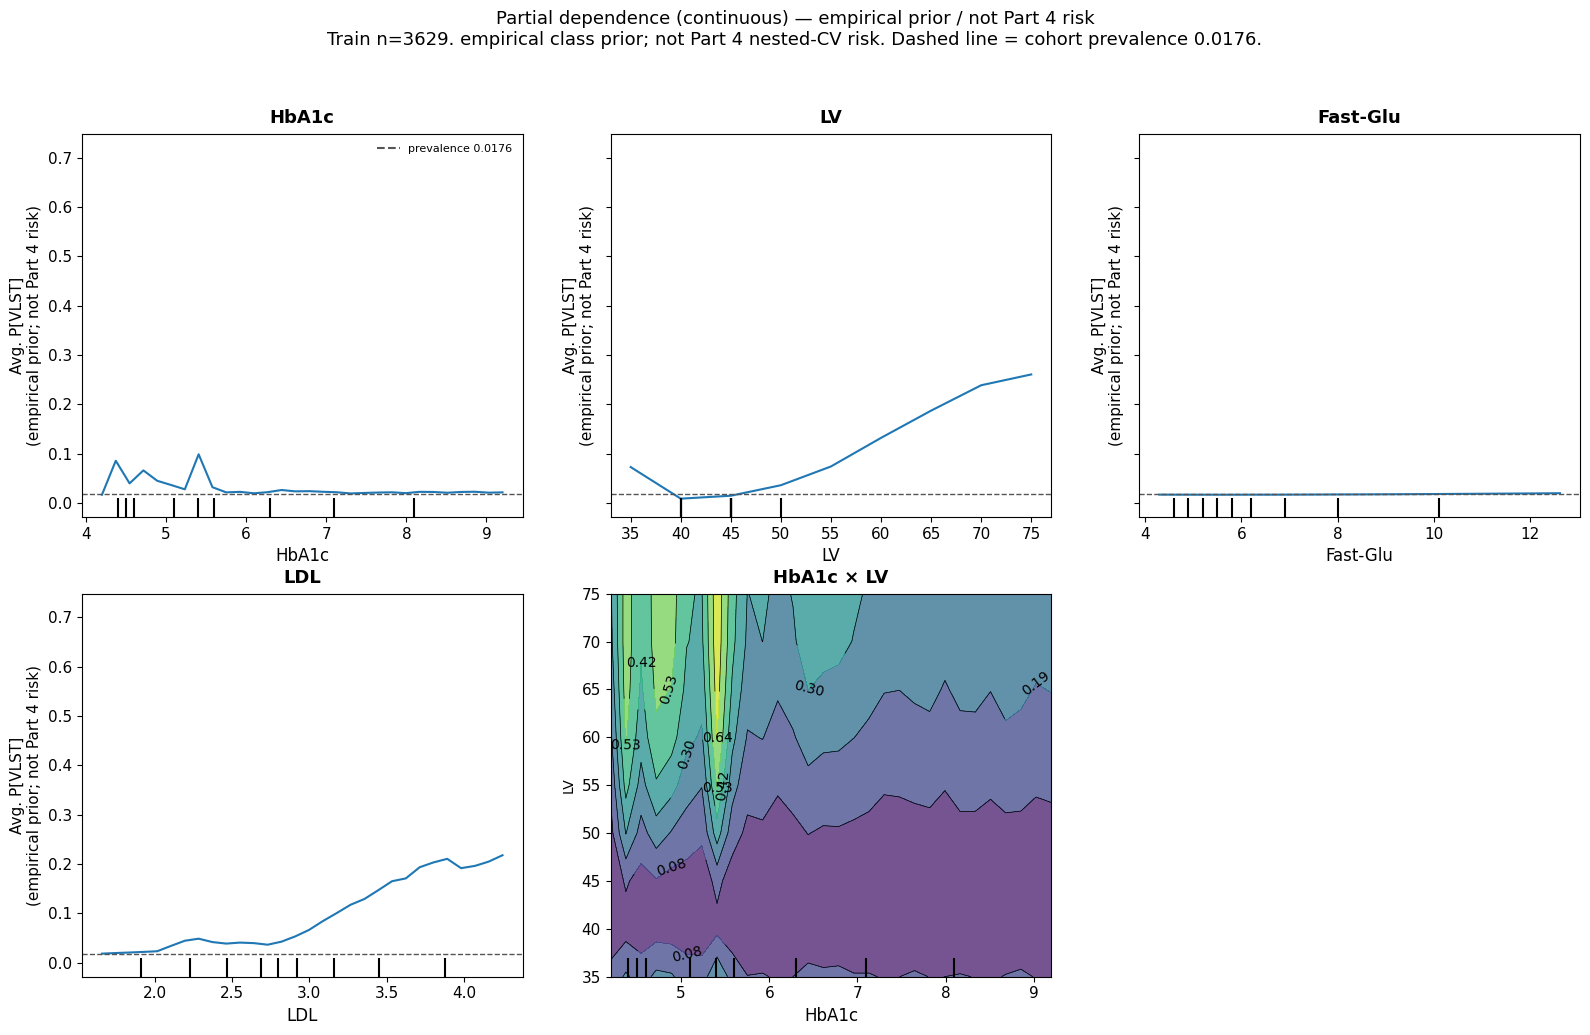

Saved: /kaggle/working/modeling_tabpfn_r3_residual/interpretability_pdp.png
Computing binary bar PDP: features=['No postdilation', 'Previous PCI', '1.1:1Post dilation', 'UA', '2-vessel disease', 'Bifurcation']...
  No postdilation: P(y=1|0)=0.0245  P(y=1|1)=0.0247  Δ=+0.0002  (empirical prior; not Part 4 risk)
  Previous PCI: P(y=1|0)=0.0174  P(y=1|1)=0.0276  Δ=+0.0101  (empirical prior; not Part 4 risk)
  1.1:1Post dilation: P(y=1|0)=0.0266  P(y=1|1)=0.0220  Δ=-0.0047  (empirical prior; not Part 4 risk)
  UA: P(y=1|0)=0.0180  P(y=1|1)=0.0215  Δ=+0.0035  (empirical prior; not Part 4 risk)
  2-vessel disease: P(y=1|0)=0.0178  P(y=1|1)=0.0179  Δ=+0.0000  (empirical prior; not Part 4 risk)
  Bifurcation: P(y=1|0)=0.0177  P(y=1|1)=0.0181  Δ=+0.0004  (empirical prior; not Part 4 risk)
Saved: /kaggle/working/modeling_tabpfn_r3_residual/interpretability_pdp_binary.csv


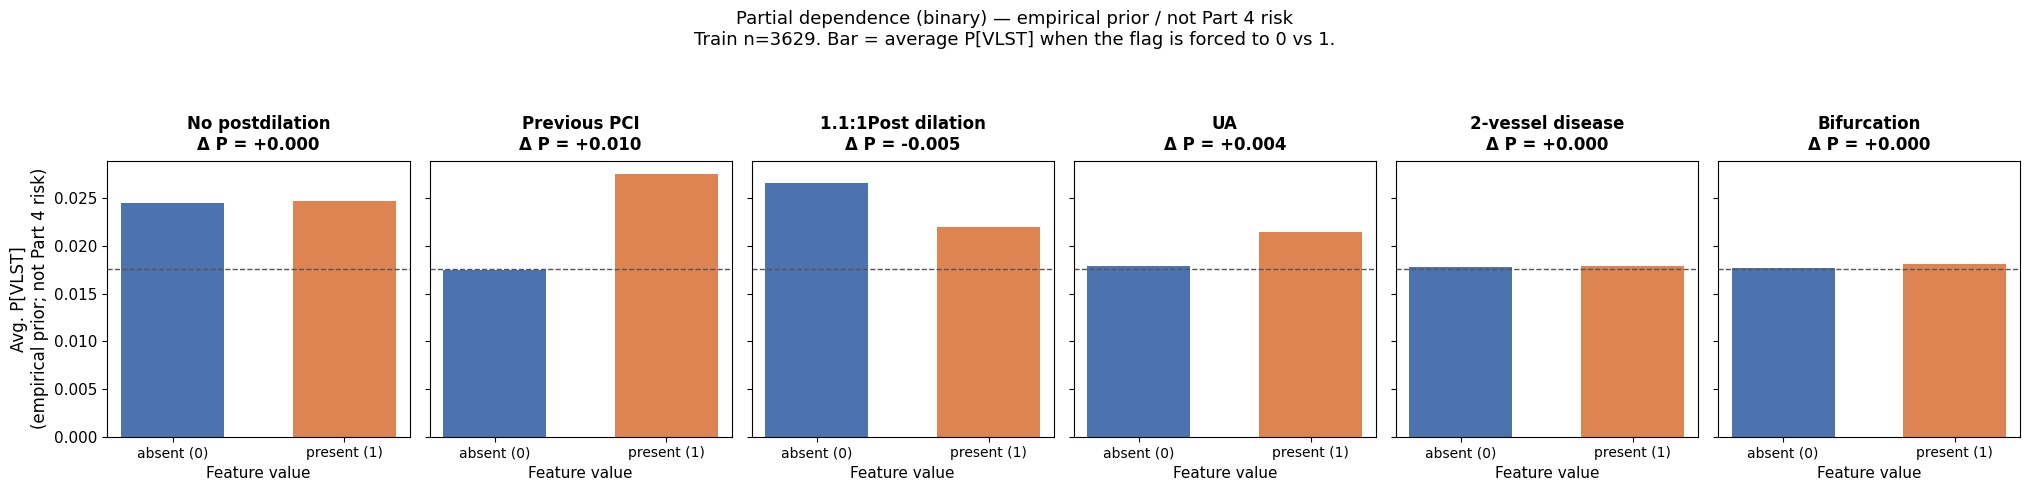

Saved: /kaggle/working/modeling_tabpfn_r3_residual/interpretability_pdp_binary.png
[2/3] done in 1965.3s | artifacts: /kaggle/working/modeling_tabpfn_r3_residual/interpretability_pdp.png, /kaggle/working/modeling_tabpfn_r3_residual/interpretability_pdp_binary.png


In [6]:
"""Partial dependence plots for the VLST TabPFN classifier.

Primary: local `tabpfn` + KV cache (0 thinking fits).
If PDP_USE_CLIENT, try the client for the *entire* PDP (fit + plots);
any failure including mid-predict HTTP 429 retries locally.

Y-axis is average P[VLST] near cohort prevalence — not Part 4 nested-CV risk.

Who is averaged: fit on train; PDP average on train.
Held-out test is reserved for SHAP (not used here).

Feature picking:
  Forward SFS often returns mostly *binary* flags. Sklearn's brute PDP crashes
  on binary features for binary classifiers, so continuous (>2 unique) features
  go to sklearn PDP. Ranking: stability frequency → MI.
  Binary flags get a 0-vs-1 bar chart.

Artifacts:
  - interpretability_pdp.png          — continuous 1-D curves (+ optional 2-D)
  - interpretability_pdp_binary.png   — bar PD for top stable binary features
  - interpretability_pdp_binary.csv   — numeric 0 vs 1 averages
"""

from __future__ import annotations

import time
import traceback
import warnings

import matplotlib.pyplot as plt

from tabpfn_extensions.interpretability.pdp import partial_dependence_plots

print("=" * 60)
print("[2/3] PDP (Partial Dependence Plots)")
print("=" * 60)

# Do not reuse old balanced-prior PNGs.
SKIP_PDP_IF_EXISTS = False
pdp_out = RESULT_DIR / "interpretability_pdp.png"
pdp_binary_out = RESULT_DIR / "interpretability_pdp_binary.png"
pdp_binary_csv = RESULT_DIR / "interpretability_pdp_binary.csv"
PDP_N_CONTINUOUS = 4
PDP_N_BINARY = 6
_prev = float(np.mean(y_train))
_pdp_ylabel = "Avg. P[VLST]\n(empirical prior; not Part 4 risk)"
_pdp_scale_note = (
    "empirical class prior; "
    f"not Part 4 nested-CV risk. Dashed line = cohort prevalence {_prev:.4f}."
)

_t0 = time.perf_counter()

if SKIP_PDP_IF_EXISTS and pdp_out.is_file() and pdp_binary_out.is_file():
    print(f"Skipping PDP -- already saved at {pdp_out} and {pdp_binary_out}")
else:
    try:
        X_pdp = np.asarray(X_train)
        n_pdp = int(X_pdp.shape[0])
        if n_pdp != len(X_train):
            raise ValueError("PDP background must be the train split.")
        print(
            f"PDP fit+average on train n={n_pdp}, events={int(np.asarray(y_train).sum())}, "
            f"controls={int((np.asarray(y_train) == 0).sum())}. {_pdp_scale_note}"
        )

        def _fit_client_clf():
            # Pinned to TABPFN_THINKING_VERSION (the bare client deferred to the server default).
            clf = _silence_client_progress(build_client_tabpfn())
            with _quiet_tabpfn_client():
                clf.fit(X_train, y_train)
            with _quiet_tabpfn_client():
                clf.predict_proba(X_train[: min(8, len(X_train))])
            return clf

        def _fit_local_clf():
            # Pinned via build_local_tabpfn: the bare constructor resolves
            # model_path="auto", and which checkpoint it loaded was never logged.
            try:
                clf = _silence_client_progress(
                    build_local_tabpfn(random_state=RANDOM_STATE, fit_mode="fit_with_cache")
                )
                with _quiet_tabpfn_client():
                    clf.fit(X_train, y_train)
                if hasattr(clf, "executor_"):
                    clf.executor_.keep_cache_on_device = True
            except (TypeError, ValueError, NotImplementedError):
                warnings.warn(
                    "Local KV cache unavailable; falling back to the pinned local "
                    "TabPFN constructor without fit_with_cache.",
                    UserWarning,
                    stacklevel=2,
                )
                clf = _silence_client_progress(build_local_tabpfn(random_state=RANDOM_STATE))
                with _quiet_tabpfn_client():
                    clf.fit(X_train, y_train)
            return clf

        def _run_pdp(clf, backend_label: str):
            print(f"PDP backend: {backend_label}")
            record_provenance(
                "pdp",
                {
                    **describe_tabpfn_model(clf, backend_label),
                    "output_scale": "probability (predict_proba[:, 1])",
                    "averaged_over": f"train n={n_pdp} (in-sample)",
                },
            )

            def _n_unique(name: str) -> int:
                col = X_pdp[:, feature_names.index(name)]
                return int(np.unique(col[~np.isnan(col)]).size)

            _ranked: list[str] = []
            for _csv, _cols in (
                (RESULT_DIR / "interpretability_feature_stability.csv", None),
                (RESULT_DIR / "interpretability_mutual_info_ranking.csv", None),
            ):
                if not _csv.is_file():
                    continue
                _df = pd.read_csv(_csv)
                if "selection_freq" in _df.columns:
                    _names = (
                        _df.sort_values("selection_freq", ascending=False)["feature"]
                        .tolist()
                    )
                else:
                    _names = _df["feature"].tolist()
                for _n in _names:
                    if _n not in _ranked and _n in feature_names:
                        _ranked.append(_n)
            for _n in feature_names:
                if _n not in _ranked:
                    _ranked.append(_n)

            _NOMINAL = {"Stent type-SES", "stent_brand"}
            _cont = [n for n in _ranked if _n_unique(n) > 2 and n not in _NOMINAL]
            _bin = [n for n in _ranked if _n_unique(n) <= 2]
            _nominal_ranked = [n for n in _ranked if n in _NOMINAL]
            if _nominal_ranked:
                print(
                    "PDP: excluding nominal stent brand from continuous curves:",
                    _nominal_ranked,
                )
            print(
                f"PDP candidates — continuous (≥3 unique): {len(_cont)}; "
                f"binary (≤2 unique): {len(_bin)}"
            )

            if not _cont:
                print("WARN: no continuous features for sklearn PDP curves.")
            else:
                _pd_names = _cont[:PDP_N_CONTINUOUS]
                _pd_idx = [feature_names.index(n) for n in _pd_names]
                pd_features: list = list(_pd_idx)
                _interact_partner = None
                if len(_cont) >= 2:
                    _interact_partner = _cont[1]
                    pd_features = _pd_idx + [
                        (_pd_idx[0], feature_names.index(_interact_partner))
                    ]

                _msg = f"Computing continuous PDP: features={_pd_names}"
                if _interact_partner is not None:
                    _msg += f" + interaction ({_pd_names[0]}, {_interact_partner})"
                print(_msg + f", grid_resolution=30, n={n_pdp}...")

                with _quiet_tabpfn_client():
                    disp = partial_dependence_plots(
                        estimator=clf,
                        X=X_pdp,
                        features=pd_features,
                        grid_resolution=30,
                        kind="average",
                        target_class=1,
                        feature_names=list(feature_names),
                    )
                fig = disp.figure_
                fig.set_size_inches(16, 10)
                if getattr(disp, "axes_", None) is not None:
                    _plot_axes = [ax for ax in np.ravel(disp.axes_) if ax is not None]
                else:
                    _plot_axes = [
                        ax for ax in fig.axes if ax.get_label() != "<colorbar>"
                    ]
                for _i_ax, _ax in enumerate(_plot_axes):
                    _xl = (_ax.get_xlabel() or "").strip()
                    _yl = (_ax.get_ylabel() or "").strip()
                    _yl_l = _yl.lower()
                    _is_2d = bool(
                        _xl
                        and _yl
                        and not _yl_l.startswith(("partial", "average", "predicted"))
                    )
                    if _is_2d:
                        _ax.set_title(
                            f"{_xl} × {_yl}", fontsize=13, fontweight="bold", pad=8
                        )
                    elif _xl:
                        _ax.set_title(_xl, fontsize=13, fontweight="bold", pad=8)
                        _ax.set_ylabel(_pdp_ylabel, fontsize=11)
                        _ax.axhline(_prev, color="#555555", ls="--", lw=1)
                        if _i_ax == 0:
                            from matplotlib.lines import Line2D

                            _ax.legend(
                                [Line2D([0], [0], color="#555555", ls="--")],
                                [f"prevalence {_prev:.4f}"],
                                fontsize=8,
                                loc="best",
                                frameon=False,
                            )
                    if _xl:
                        _ax.set_xlabel(_xl, fontsize=12)
                    _ax.tick_params(axis="both", labelsize=11)
                fig.suptitle(
                    "Partial dependence (continuous) — empirical prior / not Part 4 risk\n"
                    f"Train n={n_pdp}. {_pdp_scale_note}",
                    fontsize=13,
                    y=1.03,
                )
                fig.tight_layout(h_pad=2.5, w_pad=2.0)
                fig.savefig(pdp_out, dpi=200, bbox_inches="tight")
                plt.show()
                print(f"Saved: {pdp_out}")

            _bin_top = _bin[:PDP_N_BINARY]
            if not _bin_top:
                print("WARN: no binary features for bar PDP.")
            else:
                print(f"Computing binary bar PDP: features={_bin_top}...")
                _bar_vals = []
                for _name in _bin_top:
                    _j = feature_names.index(_name)
                    _X0 = X_pdp.copy()
                    _X1 = X_pdp.copy()
                    _X0[:, _j] = 0.0
                    _X1[:, _j] = 1.0
                    with _quiet_tabpfn_client():
                        _p0 = float(clf.predict_proba(_X0)[:, 1].mean())
                        _p1 = float(clf.predict_proba(_X1)[:, 1].mean())
                    _bar_vals.append((_name, _p0, _p1, _p1 - _p0))
                    print(
                        f"  {_name}: P(y=1|0)={_p0:.4f}  P(y=1|1)={_p1:.4f}  "
                        f"Δ={_p1 - _p0:+.4f}  (empirical prior; not Part 4 risk)"
                    )

                _bar_df = pd.DataFrame(
                    [
                        {
                            "feature": n,
                            "p_absent": p0,
                            "p_present": p1,
                            "delta": d,
                            "scale": "empirical_prior_not_part4",
                            "n": n_pdp,
                            "prevalence": _prev,
                        }
                        for n, p0, p1, d in _bar_vals
                    ]
                )
                _bar_df.to_csv(pdp_binary_csv, index=False)
                print(f"Saved: {pdp_binary_csv}")

                _n = len(_bar_vals)
                fig, axes = plt.subplots(1, _n, figsize=(3.4 * _n, 4.5), sharey=True)
                if _n == 1:
                    axes = [axes]
                for ax, (_name, _p0, _p1, _delta) in zip(axes, _bar_vals):
                    ax.bar([0, 1], [_p0, _p1], color=["#4C72B0", "#DD8452"], width=0.6)
                    ax.axhline(_prev, color="#555555", ls="--", lw=1)
                    ax.set_xticks([0, 1])
                    ax.set_xticklabels(["absent (0)", "present (1)"], fontsize=10)
                    ax.set_title(
                        f"{_name}\nΔ P = {_delta:+.3f}",
                        fontsize=12,
                        fontweight="bold",
                        pad=8,
                    )
                    ax.set_xlabel("Feature value", fontsize=11)
                    ax.tick_params(axis="y", labelsize=11)
                axes[0].set_ylabel(_pdp_ylabel, fontsize=12)
                fig.suptitle(
                    "Partial dependence (binary) — empirical prior / not Part 4 risk\n"
                    f"Train n={n_pdp}. Bar = average P[VLST] when the flag is forced to 0 vs 1.",
                    fontsize=13,
                    y=1.08,
                )
                fig.tight_layout()
                fig.savefig(pdp_binary_out, dpi=200, bbox_inches="tight")
                plt.show()
                print(f"Saved: {pdp_binary_out}")


        if PDP_USE_CLIENT:
            try:
                print(
                    f"Optional: fitting tabpfn-client "
                    f"(thinking={INTERP_THINKING_MODE})..."
                )
                clf = _fit_client_clf()
                _run_pdp(clf, "tabpfn-client + thinking")
            except Exception as _client_err:
                print(
                    f"Client PDP failed ({type(_client_err).__name__}: {_client_err}). "
                    f"Backup: local tabpfn + KV cache (0 thinking fits)..."
                )
                traceback.print_exc()
                clf = _fit_local_clf()
                _run_pdp(clf, "local tabpfn + KV cache")
        else:
            print("Fitting local TabPFN for PDP (KV cache; 0 client thinking fits)...")
            clf = _fit_local_clf()
            _run_pdp(clf, "local tabpfn + KV cache")

    except Exception as _pdp_err:
        print(
            f"[2/3] PDP FAILED — logging and continuing to the next section. "
            f"{type(_pdp_err).__name__}: {_pdp_err}"
        )
        traceback.print_exc()

_elapsed = time.perf_counter() - _t0
print(
    f"[2/3] done in {_elapsed:.1f}s | artifacts: {pdp_out}, {pdp_binary_out}"
)


### Feature importance report — [3/3]

Honest, consensus ranking of the most important features. No single method is
trusted alone — we aggregate the local signals computed above:

1. **mutual_info_classif** — univariate association on **train**
2. **Stability selection frequency** — how often forward SFS keeps a feature
   across `STABILITY_N_SEEDS` train resamples (the reliability signal)
3. **SHAP mean(|value|)** — model attribution magnitude on the **held-out** split

Ranking uses **Borda-style mean of normalized ranks** across the available
continuous signals (robust to any one noisy method), with `n_methods` (out of
3) as a consensus column. Report the **top 15** as *associations* with stent
thrombosis under TabPFN — exploratory, not causal, on a ~2% prevalence cohort.
→ `interpretability_feature_importance_report.csv` + `.png`

SHAP comes from `tabpfn_interpretability_shap.ipynb`. On Kaggle, attach that notebook's output for the **same variant** (its folder name must equal this run's `RESULT_DIR` name, e.g. `modeling_tabpfn_r3_residual`) before running this cell. Without it the report runs on MI + stability only, prints a warning, leaves the SHAP column empty and marks the figure "incomplete". Locally, `code/modeling/tools/rebuild_consensus_report.py` rebuilds the full report from the two downloaded output folders.


[3/3] Feature importance report (consensus)
Using interpretability_shap_mean_abs.csv from /kaggle/input/notebooks/amirinho661/shap-full/modeling_tabpfn_r3_residual/interpretability_shap_mean_abs.csv

Aggregated from signals: ['mutual_info', 'selection_freq', 'shap_mean_abs']

Top 15 features (honest consensus ranking):
 rank                 feature  importance_score  n_methods  selection_freq  shap_mean_abs  mutual_info  in_mi_top  in_shap_top
    1                   HbA1c          0.984234          3           1.000       0.408885     0.007259       True         True
    2                     LDL          0.975225          3           0.625       0.364817     0.009312       True         True
    3                      LV          0.966216          3           1.000       0.284771     0.009076       True         True
    4         No postdilation          0.957207          3           0.625       0.327638     0.007287       True         True
    5          Stent type-SES          0.921

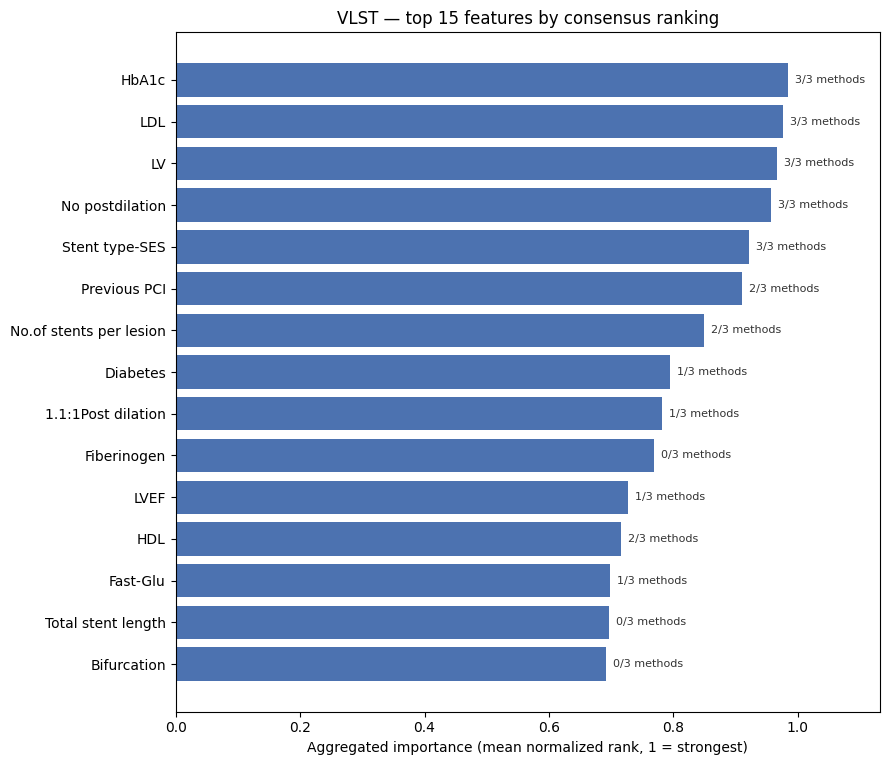

Saved: /kaggle/working/modeling_tabpfn_r3_residual/interpretability_feature_importance_report.png


In [7]:
"""Honest feature-importance report for VLST — consensus of local signals.

Combines train mutual_info, train stability-selection frequency, and
held-out SHAP mean(|value|) into one ranked table. Ranking = Borda-style mean
of normalized ranks over the available continuous signals; `n_methods` counts
how many methods flag each feature. Report the TOP_K as *associations* with
stent thrombosis under TabPFN — exploratory, not causal, on a ~2% prevalence cohort.
Reads only CSV artifacts, so it costs 0 thinking fits and can be re-run freely.
"""

from __future__ import annotations

import matplotlib.pyplot as plt

print("=" * 60)
print("[3/3] Feature importance report (consensus)")
print("=" * 60)

TOP_K = 15

_report_csv = RESULT_DIR / "interpretability_feature_importance_report.csv"
_report_png = RESULT_DIR / "interpretability_feature_importance_report.png"

def _artifact_csv(name):
    """Prefer RESULT_DIR; else a CSV attached from the sibling Kaggle notebook.

    Only files under a directory named RESULT_DIR.name are accepted, so an attached
    output of another analysis variant (e.g. the R1 SHAP run under an R3 report)
    is never mixed in.
    """
    direct = RESULT_DIR / name
    if direct.is_file():
        return direct
    hits = []
    for root in (Path("/kaggle/input"), Path("/kaggle/working")):
        if root.is_dir():
            hits.extend(
                p for p in root.rglob(name)
                if p.is_file() and p.parent.name == RESULT_DIR.name and p.resolve() != direct.resolve()
            )
    if hits:
        hits.sort(key=lambda p: p.stat().st_mtime, reverse=True)
        print(f"Using {name} from {hits[0]}")
        return hits[0]
    return direct

_mi_csv = _artifact_csv("interpretability_mutual_info_ranking.csv")
_stab_csv = _artifact_csv("interpretability_feature_stability.csv")
_shap_csv = _artifact_csv("interpretability_shap_mean_abs.csv")

_report = pd.DataFrame({"feature": list(feature_names)})
_signals = []  # continuous columns used for rank aggregation

# --- mutual information ---------------------------------------------------
if _mi_csv.is_file():
    _mi = pd.read_csv(_mi_csv)[["feature", "mutual_info"]]
    _report = _report.merge(_mi, on="feature", how="left")
    # Do not fill missing MI with 0 — that invented zeros for names outside a
    # truncated top-15 CSV (Cre, No.of stents per lesion). Leave NaN.
    _mi_top_names = (
        _mi.sort_values("mutual_info", ascending=False)
        .head(TOP_K)["feature"]
    )
    _report["in_mi_top"] = _report["feature"].isin(_mi_top_names)
    _signals.append("mutual_info")
else:
    print(f"WARN: {_mi_csv.name} missing — run [1/3] first.")
    _report["mutual_info"] = np.nan
    _report["in_mi_top"] = False

# --- stability selection frequency ---------------------------------------
if _stab_csv.is_file():
    _stab = pd.read_csv(_stab_csv)[["feature", "selection_freq"]]
    _report = _report.merge(_stab, on="feature", how="left")
    _report["selection_freq"] = _report["selection_freq"].fillna(0.0)
    _signals.append("selection_freq")
else:
    print(f"WARN: {_stab_csv.name} missing — run [1/3] stability step first.")
    _report["selection_freq"] = np.nan

# --- SHAP mean(|value|) --------------------------------------------------
if _shap_csv.is_file():
    _shap = pd.read_csv(_shap_csv)[["feature", "shap_mean_abs"]]
    _report = _report.merge(_shap, on="feature", how="left")
    _report["shap_mean_abs"] = _report["shap_mean_abs"].fillna(0.0)
    _shap_top = set(
        _shap.sort_values("shap_mean_abs", ascending=False).head(TOP_K)["feature"]
    )
    _report["in_shap_top"] = _report["feature"].isin(_shap_top)
    _signals.append("shap_mean_abs")
else:
    # NaN, not 0: a column of zeros reads as "SHAP found nothing".
    print(
        f"WARN: {_shap_csv.name} missing. Attach the output of tabpfn_interpretability_shap.ipynb "
        f"for the same variant ({RESULT_DIR.name}) and re-run this cell; until then the "
        "report is incomplete (no SHAP column)."
    )
    _report["shap_mean_abs"] = np.nan
    _report["in_shap_top"] = False

# --- consensus count (out of the methods available) ---------------------
N_METHODS_AVAILABLE = len(_signals)
_report["n_methods"] = (
    _report["in_mi_top"].astype(int)
    + (_report["selection_freq"] >= 0.5).astype(int)
    + _report["in_shap_top"].astype(int)
)

# --- Borda rank aggregation over available continuous signals ------------
if _signals:
    _norm = []
    for _c in _signals:
        _r = _report[_c].rank(method="average", ascending=True)  # 1 = best
        _norm.append((_r - 1) / max(len(_report) - 1, 1))
    _report["importance_score"] = np.mean(_norm, axis=0)
else:
    print("WARN: no continuous signals available — cannot rank.")
    _report["importance_score"] = 0.0

_report = _report.sort_values(
    ["importance_score", "n_methods"], ascending=[False, False]
).reset_index(drop=True)
_report.insert(0, "rank", range(1, len(_report) + 1))

_cols = [
    "rank", "feature", "importance_score", "n_methods",
    "selection_freq", "shap_mean_abs", "mutual_info",
    "in_mi_top", "in_shap_top",
]
_report = _report[[c for c in _cols if c in _report.columns]]
_report.to_csv(_report_csv, index=False)

_topk = _report.head(TOP_K)
print(f"\nAggregated from signals: {_signals}")
print(f"\nTop {TOP_K} features (honest consensus ranking):")
print(_topk.to_string(index=False))
print(f"\nSaved: {_report_csv}")

# --- horizontal bar chart of top-k --------------------------------------
_bars = _topk.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.45 * len(_bars) + 1))
ax.barh(_bars["feature"], _bars["importance_score"], color="#4C72B0")
for _i, (_score, _n) in enumerate(zip(_bars["importance_score"], _bars["n_methods"])):
    ax.text(_score, _i, f"  {_n}/{N_METHODS_AVAILABLE} methods", va="center", fontsize=8, color="#333")
ax.set_xlabel("Aggregated importance (mean normalized rank, 1 = strongest)")
ax.set_title(
    f"VLST — top {TOP_K} features by consensus ranking"
    + ("" if "shap_mean_abs" in _signals else " (no SHAP: incomplete)")
)
ax.margins(x=0.15)
fig.tight_layout()
fig.savefig(_report_png, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {_report_png}")


### Provenance record

Printed so the committed outputs carry the model, checkpoint, package versions, settings and output scale of every artefact in this run.


In [8]:
_prov_path = RESULT_DIR / "interpretability_model_provenance.json"
print(_prov_path.read_text() if _prov_path.is_file() else f"No provenance file at {_prov_path}")


{
  "runtime": {
    "python": "3.12.13",
    "tabpfn": "9.2.0",
    "tabpfn-client": "0.7.1",
    "tabpfn-extensions": "0.6.3",
    "shapiq": "1.8.0",
    "shap": "0.54.1",
    "scikit-learn": "1.6.1",
    "numpy": "2.0.2",
    "pandas": "2.3.3",
    "torch": "2.10.0+cu128",
    "device": "Tesla T4",
    "recorded_utc": "2026-11-16T11:10:29+00:00"
  },
  "data": {
    "raw_csv": "/kaggle/input/datasets/amirinho661/vlst-figshare-7409606/VLST.csv",
    "raw_csv_sha256": "0b8cf3da4064496a6702b0d0b5736e80306a2b8c141f9d8a9d896cbfab00d93e",
    "analysis_variant": "r3_residual",
    "dropped_features": [
      "Time since stent implantation",
      "WBC",
      "Aspirin",
      "Clopidogrel",
      "Ticagrelor",
      "DAPT",
      "CaI"
    ],
    "clinical_quantization": {
      "Cre": 0,
      "CaI": 2,
      "Fiberinogen": 1,
      "Fast-Glu": 1
    },
    "recompute_egfr_from_creatinine": true,
    "r3_residual_artefacts": true,
    "r3_cai_handling": "drop",
    "stent_codebook": "fit